# 05 - Hyperparameter Analysis

**Phase 7 (P7.5) - Targeted hyperparameter sweep review**

This notebook turns the P7.3 sweep record into a reviewable, visual comparison. It reads:

- `data/processed/hparam_sweep_notes.md` - the written record of every variation
- `results/hparam_sweep/summary_table.csv` - one row per run, ranked
- `results/hparam_sweep/comparison_plot.png` - the P7.3 evidence figure
- `runs/<experiment>/<timestamp>/metrics.csv` - per-epoch logs
- `runs/<experiment>/<timestamp>/config.yaml` - the exact configuration of each run

**Scope actually covered by P7.3.** The plan's sweep menu offers four axes (loss
weighting, base learning rate, batch size, unfreeze boundaries). Three variations were run,
and every one of them moved a **learning-rate** value; batch size, loss weights and the
phase schedule were held at their P7.1 values throughout. Section 1 proves that
programmatically from the run configs rather than asserting it, and Section 4 documents the
axes that were deliberately left alone.

**Provenance.** Every number below is validation-split performance. The test split has not
been accessed at any point in Phase 7, and the winning configuration was named in writing
(`hparam_sweep_notes.md`, "Decision - 2026-11-19") before this notebook was built.

> No training or evaluation happens here. This notebook only reads artifacts the script
> pipeline produced, per the project rule that notebooks never contain pipeline logic.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

ROOT = Path().resolve().parent  # notebook lives in notebooks/
sys.path.insert(0, str(ROOT))

from src.config import load_merged_config  # noqa: E402
from src.data.splits import compute_class_weights  # noqa: E402

RESULTS = ROOT / "results" / "hparam_sweep"
PROCESSED = ROOT / "data" / "processed"
SPLITS = PROCESSED / "splits"

sns.set_theme(style="darkgrid", palette="muted")
plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)

RUNS = pd.DataFrame(
    [
        ("Run 1", "sense_full", "runs/sense_full/20261114T122905Z", "completed"),
        (
            "V1-A1",
            "sense_full_lr1e-3",
            "runs/sense_full_lr1e-3/20261115T142011Z",
            "diverged",
        ),
        (
            "V1-A2",
            "sense_full_lr1e-3",
            "runs/sense_full_lr1e-3/20261117T162825Z",
            "diverged",
        ),
        ("V1-A3", "sense_full_lr3e-4", "runs/sense_full_lr3e-4/20261117T172308Z", "completed"),
        (
            "V2",
            "sense_full_lr3e-4_p3lr0.1",
            "runs/sense_full_lr3e-4_p3lr0.1/20261119T063459Z",
            "completed",
        ),
        (
            "V3",
            "sense_full_lr3e-4_p3lr0.3",
            "runs/sense_full_lr3e-4_p3lr0.3/20261119T120231Z",
            "completed",
        ),
    ],
    columns=["run", "experiment", "run_dir", "status"],
)
RUNS["run_dir"] = RUNS["run_dir"].map(lambda p: ROOT / p)

# The summary table identifies runs by experiment name; map back to the short labels.
RUN_LABEL = dict(zip(RUNS["experiment"], RUNS["run"]))

print("ROOT:", ROOT)
RUNS


ROOT: C:\Users\Tamim Syeedur Rahman\All Codes\sense-project


,run,experiment,run_dir,status
0,Run 1,sense_full,C:\Users\Tamim Syeedur Rahman\All Codes\sense-...,completed
1,V1-A1,sense_full_lr1e-3,C:\Users\Tamim Syeedur Rahman\All Codes\sense-...,diverged
2,V1-A2,sense_full_lr1e-3,C:\Users\Tamim Syeedur Rahman\All Codes\sense-...,diverged
3,V1-A3,sense_full_lr3e-4,C:\Users\Tamim Syeedur Rahman\All Codes\sense-...,completed
4,V2,sense_full_lr3e-4_p3lr0.1,C:\Users\Tamim Syeedur Rahman\All Codes\sense-...,completed
5,V3,sense_full_lr3e-4_p3lr0.3,C:\Users\Tamim Syeedur Rahman\All Codes\sense-...,completed


## 1. Sweep scope - which axes actually moved

P7.3 asked for at most 3-4 variations, each changing exactly one axis so the effect is
attributable. The table below is the P7.3 summary table, unchanged.


In [2]:
summary = pd.read_csv(RESULTS / "summary_table.csv")
summary["rank"] = summary["rank"].astype("Int64")  # blank for diverged runs

completed = summary[summary["status"] == "completed"].sort_values(
    "best_val_macro_f1", ascending=False
)
diverged = summary[summary["status"] == "diverged"]

cols = [
    "rank",
    "experiment",
    "status",
    "best_epoch",
    "best_val_macro_f1",
    "best_val_accuracy",
    "best_val_min_class_accuracy",
    "phase1_mean_macro_f1",
    "phase2_mean_macro_f1",
    "phase3_mean_macro_f1",
    "epochs_logged",
    "wall_time_hms",
]
print(
    f"{len(summary)} runs recorded: "
    f"{len(completed)} completed, {len(diverged)} diverged"
)
display(summary[cols])


6 runs recorded: 4 completed, 2 diverged


,rank,experiment,status,best_epoch,best_val_macro_f1,best_val_accuracy,best_val_min_class_accuracy,phase1_mean_macro_f1,phase2_mean_macro_f1,phase3_mean_macro_f1,epochs_logged,wall_time_hms
0,1,sense_full_lr3e-4_p3lr0.3,completed,45,0.956383,0.965923,0.914286,0.576761,0.782731,0.934816,50,3h14m00s
1,2,sense_full_lr3e-4_p3lr0.1,completed,45,0.929634,0.950101,0.857143,0.574852,0.797725,0.915468,50,3h10m12s
2,3,sense_full_lr3e-4,completed,41,0.894619,0.916836,0.827586,0.587017,0.799992,0.876272,50,2h51m25s
3,4,sense_full,completed,49,0.876609,0.898174,0.770492,0.643645,0.777820,0.849274,50,2h40m45s
4,<NA>,sense_full_lr1e-3,diverged,5,0.546250,0.642191,0.241379,0.271158,0.011730,NaN,14,0h43m45s
5,<NA>,sense_full_lr1e-3,diverged,2,0.309664,0.400000,0.000000,0.278159,NaN,NaN,4,0h10m46s


### Which configuration keys differ between the runs?

Every run's `config.yaml` is loaded through `src.config.load_merged_config` and flattened.
Any key whose value differs across the six runs is shown below. This is the evidence that the
sweep stayed single-axis: **only two keys moved**, and both are learning rates.


In [3]:
def flatten(d, prefix=""):
    out = {}
    for k, v in d.items():
        key = f"{prefix}{k}"
        if isinstance(v, dict):
            out.update(flatten(v, key + "."))
        else:
            out[key] = v
    return out


cfgs = {
    row.run: flatten(load_merged_config(row.run_dir / "config.yaml"))
    for row in RUNS.itertuples()
}
all_keys = sorted(set().union(*(c.keys() for c in cfgs.values())))

differing = []
for key in all_keys:
    values = [cfgs[row.run].get(key, "<absent>") for row in RUNS.itertuples()]
    if len({str(v) for v in values}) > 1:
        differing.append(
            {"config key": key, **{row.run: v for row, v in zip(RUNS.itertuples(), values)}}
        )

axes = pd.DataFrame(differing)
print(f"{len(axes)} of {len(all_keys)} config keys differ across the {len(RUNS)} runs")
display(axes.set_index("config key").T)


2 of 49 config keys differ across the 6 runs


config key,training.base_lr,training.phases.phase3.lr_scale
Run 1,0.0001,0.01
V1-A1,0.0010,0.01
V1-A2,0.0010,0.01
V1-A3,0.0003,0.01
V2,0.0003,0.10
V3,0.0003,0.30


## 2. Learning-rate comparison

Two views of the same axis:

- **Left** - the scheduled learning rate actually logged each epoch (`metrics.csv`,
  `learning_rate` column). This is the head/base parameter group; during phase 3 the backbone
  group runs at `base_lr x phase3.lr_scale`.
- **Right** - best validation macro F1 against the nominal phase-3 backbone learning rate
  (`base_lr x phase3.lr_scale`), which is the quantity the sweep was really moving.

The two `base_lr 1e-3` attempts are excluded from the right panel: they diverged in phase 2,
before phase 3 began, so their peak is not a phase-3 result and would not sit on this axis.


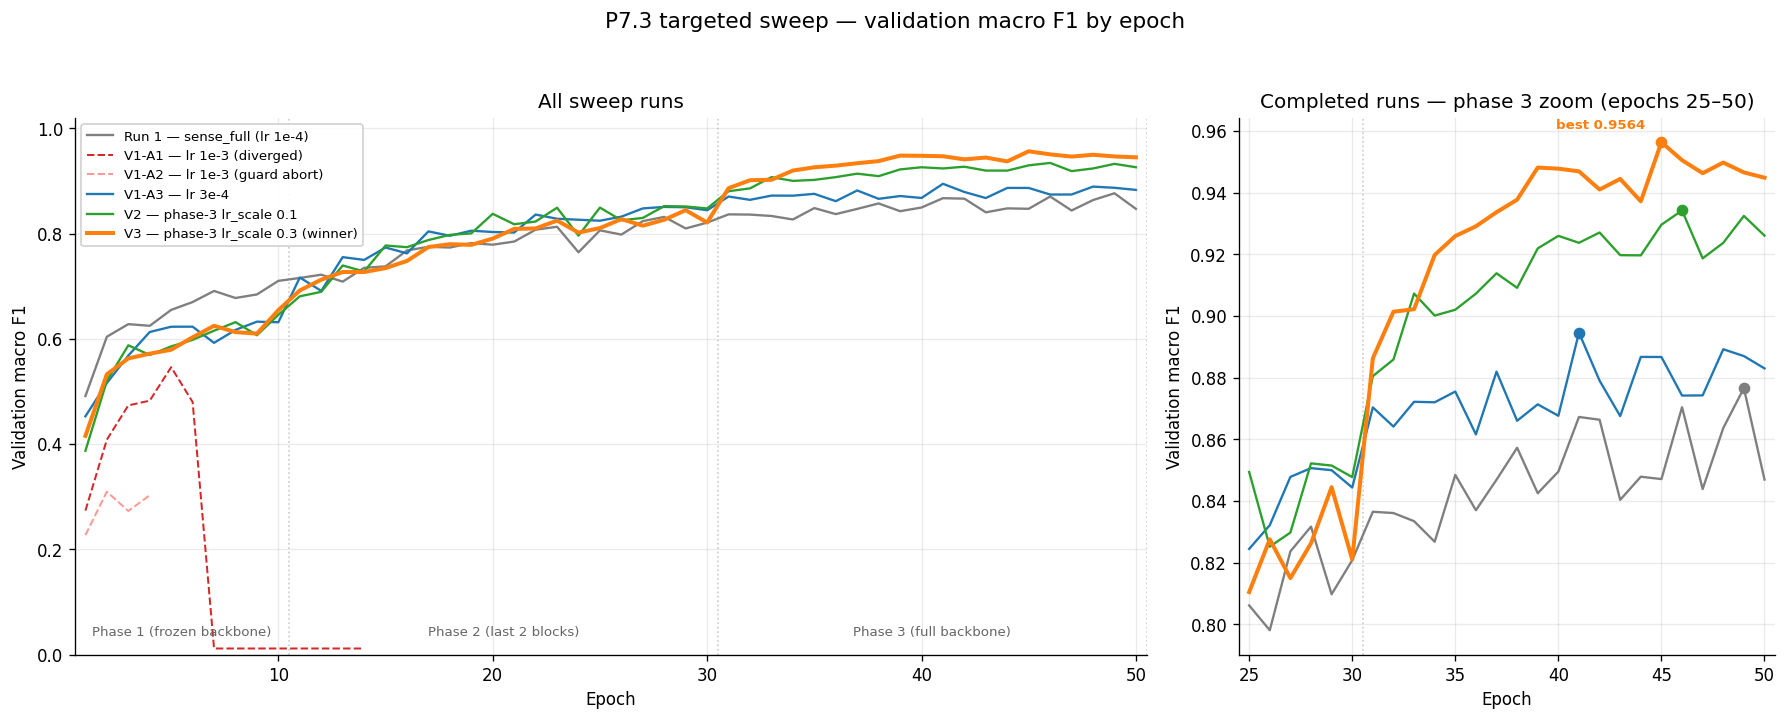

In [4]:
display(Image(filename=str(RESULTS / "comparison_plot.png")))


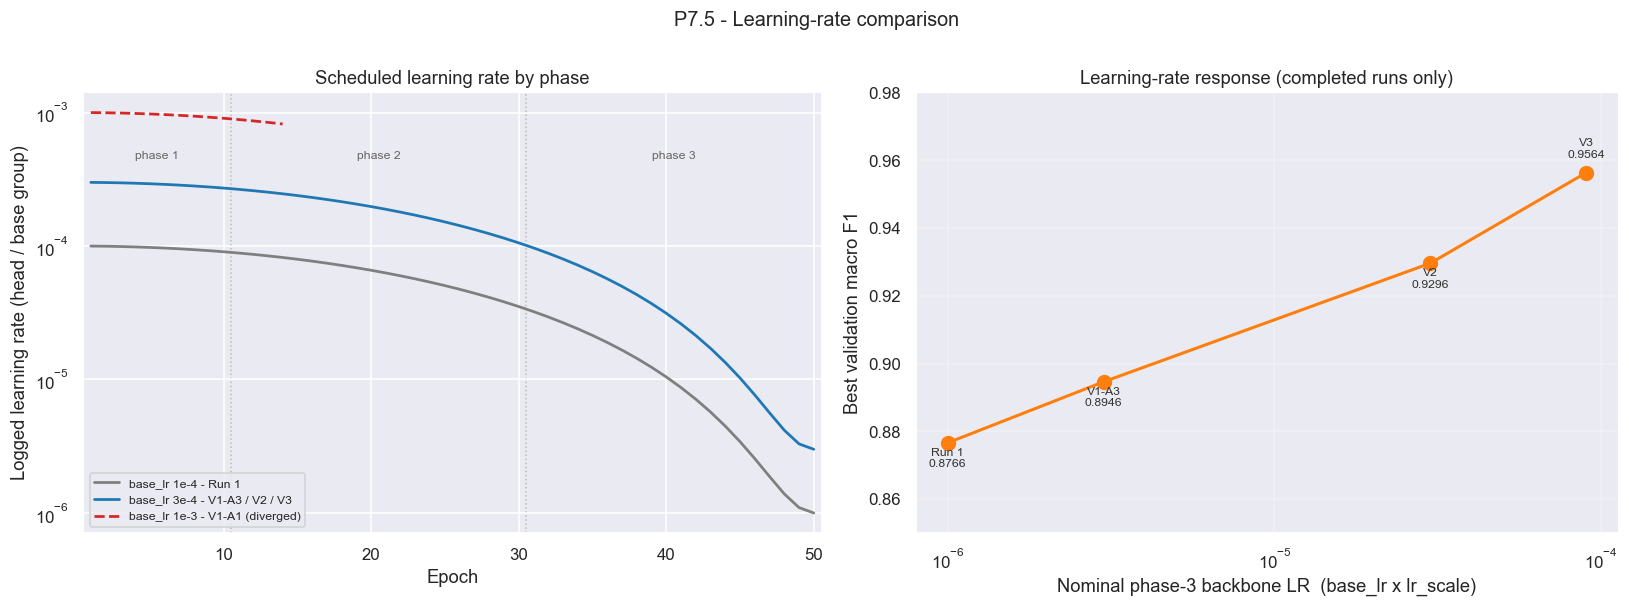

saved results\hparam_sweep\lr_comparison.png


In [5]:
fig, (ax_sched, ax_axis) = plt.subplots(
    1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.05, 1]}
)

sched = [
    ("base_lr 1e-4 - Run 1", "runs/sense_full/20261114T122905Z", "#7f7f7f", "-"),
    (
        "base_lr 3e-4 - V1-A3 / V2 / V3",
        "runs/sense_full_lr3e-4/20261117T172308Z",
        "#1f77b4",
        "-",
    ),
    (
        "base_lr 1e-3 - V1-A1 (diverged)",
        "runs/sense_full_lr1e-3/20261115T142011Z",
        "#d62728",
        "--",
    ),
]
for label, rel, color, style in sched:
    df = pd.read_csv(ROOT / rel / "metrics.csv")
    ax_sched.plot(
        df["epoch"], df["learning_rate"], label=label, color=color, linestyle=style,
        linewidth=1.8,
    )

for x in (10.5, 30.5):
    ax_sched.axvline(x, color="#bbbbbb", linestyle=":", linewidth=1.0, zorder=0)
for name, mid in (("phase 1", 5.5), ("phase 2", 20.5), ("phase 3", 40.5)):
    ax_sched.text(mid, 4.5e-4, name, ha="center", fontsize=8, color="#666666")

ax_sched.set_yscale("log")
ax_sched.set_xlabel("Epoch")
ax_sched.set_ylabel("Logged learning rate (head / base group)")
ax_sched.set_title("Scheduled learning rate by phase")
ax_sched.set_xlim(0.5, 50.5)
ax_sched.legend(loc="lower left", fontsize=8)

# --- right: the axis the sweep actually explored ---
lr_rows = []
for _, r in completed.iterrows():
    cfg = load_merged_config(ROOT / r["run_dir"] / "config.yaml")
    base_lr = float(cfg["training"]["base_lr"])
    scale = float(cfg["training"]["phases"]["phase3"]["lr_scale"])
    lr_rows.append(
        {
            "run": RUN_LABEL.get(r["experiment"], r["experiment"]),
            "experiment": r["experiment"],
            "base_lr": base_lr,
            "phase3_lr_scale": scale,
            "nominal_p3_backbone_lr": base_lr * scale,
            "best_epoch": int(r["best_epoch"]),
            "best_val_macro_f1": float(r["best_val_macro_f1"]),
            "best_val_accuracy": float(r["best_val_accuracy"]),
            "best_val_min_class_accuracy": float(r["best_val_min_class_accuracy"]),
        }
    )
lr_axis = pd.DataFrame(lr_rows).sort_values("nominal_p3_backbone_lr").reset_index(drop=True)
lr_axis["delta_vs_run1"] = lr_axis["best_val_macro_f1"] - lr_axis["best_val_macro_f1"].iloc[0]

ax_axis.plot(
    lr_axis["nominal_p3_backbone_lr"],
    lr_axis["best_val_macro_f1"],
    marker="o",
    markersize=9,
    color="#ff7f0e",
    linewidth=2,
)
offsets = [(0, -16), (0, -16), (0, -16), (0, 10)]
for i, r in lr_axis.iterrows():
    dx, dy = offsets[i]
    ax_axis.annotate(
        f"{r['run']}\n{r['best_val_macro_f1']:.4f}",
        xy=(r["nominal_p3_backbone_lr"], r["best_val_macro_f1"]),
        xytext=(dx, dy),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="#333333",
    )

ax_axis.set_xscale("log")
ax_axis.set_xlabel("Nominal phase-3 backbone LR  (base_lr x lr_scale)")
ax_axis.set_ylabel("Best validation macro F1")
ax_axis.set_title("Learning-rate response (completed runs only)")
ax_axis.set_ylim(0.85, 0.98)
ax_axis.grid(alpha=0.25)

fig.suptitle("P7.5 - Learning-rate comparison", fontsize=13, y=1.0)
fig.tight_layout()
out = RESULTS / "lr_comparison.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print("saved", out.relative_to(ROOT))


In [6]:
show = lr_axis.copy()
show["nominal_p3_backbone_lr"] = show["nominal_p3_backbone_lr"].map("{:.1e}".format)
show["base_lr"] = show["base_lr"].map("{:.1e}".format)
display(
    show[
        [
            "run",
            "base_lr",
            "phase3_lr_scale",
            "nominal_p3_backbone_lr",
            "best_epoch",
            "best_val_macro_f1",
            "delta_vs_run1",
            "best_val_min_class_accuracy",
        ]
    ]
)

best = lr_axis.loc[lr_axis["best_val_macro_f1"].idxmax()]
runner_up = lr_axis["best_val_macro_f1"].nlargest(2).iloc[1]
print(
    f"Best phase-3 backbone LR: {best['nominal_p3_backbone_lr']:.1e} "
    f"({best['run']}) -> macro F1 {best['best_val_macro_f1']:.6f}"
)
print(f"Margin over runner-up: {best['best_val_macro_f1'] - runner_up:+.6f}")


,run,base_lr,phase3_lr_scale,nominal_p3_backbone_lr,best_epoch,best_val_macro_f1,delta_vs_run1,best_val_min_class_accuracy
0,Run 1,1.0e-04,0.01,1.0e-06,49,0.876609,0.000000,0.770492
1,V1-A3,3.0e-04,0.01,3.0e-06,41,0.894619,0.018010,0.827586
2,V2,3.0e-04,0.10,3.0e-05,45,0.929634,0.053025,0.857143
3,V3,3.0e-04,0.30,9.0e-05,45,0.956383,0.079774,0.914286


Best phase-3 backbone LR: 9.0e-05 (V3) -> macro F1 0.956383
Margin over runner-up: +0.026749


**Reading the response.** The three completed configurations that differ only in learning
rate form a monotonic sequence: 1e-6 -> 3e-6 -> 3e-5 -> 9e-5 nominal phase-3 backbone LR,
with best macro F1 rising 0.8766 -> 0.8946 -> 0.9296 -> 0.9564. The response is still
positive at the largest value tried, but the *phase-3 mean* increments shrink
(+0.0392, then +0.0193), which is why the sweep stopped at three variations rather than
climbing further.

**Why the nominal LR overstates the real one.** The cosine schedule has decayed to roughly
0.32 of peak by the time phase 3 starts at epoch 31, so the actual backbone LR in phase 3 is
about a third of the nominal figure (≈2.9e-5 for V3, ≈9.7e-6 for V2). This is why a nominal
9e-5 is still well below the 1e-3 head LR that diverged twice.

**The divergences are a separate finding.** Both `base_lr 1e-3` attempts died in phase 2
(epoch 6 and epoch 5, batch 243) - long before phase 3. They are evidence that 1e-3 is
outside the pipeline's stability region, not evidence about the phase-3 axis.


## 3. Early-stopping behaviour

Patience is 10 epochs on validation macro F1. If a run ever went 10 consecutive epochs without
improving, it would stop early. The table records how close each run came to that, and whether
the 50-epoch budget was actually the binding constraint.


In [7]:
early_rows = []
for _, r in completed.iterrows():
    df = pd.read_csv(ROOT / r["run_dir"] / "metrics.csv")
    peak = df.loc[df["val_macro_f1"].idxmax()]
    final = df.iloc[-1]
    early_rows.append(
        {
            "run": RUN_LABEL.get(r["experiment"], r["experiment"]),
            "epochs_run": len(df),
            "best_epoch": int(peak["epoch"]),
            "epochs_after_peak": int(final["epoch"] - peak["epoch"]),
            "peak_f1": round(float(peak["val_macro_f1"]), 6),
            "final_f1": round(float(final["val_macro_f1"]), 6),
            "peak_to_final": round(
                float(final["val_macro_f1"] - peak["val_macro_f1"]), 6
            ),
            "early_stop_triggered": len(df) < 50,
        }
    )
early = pd.DataFrame(early_rows).sort_values("peak_f1", ascending=False).reset_index(drop=True)
display(early)

print(
    f"runs that triggered early stopping: {int(early['early_stop_triggered'].sum())} "
    f"of {len(early)}"
)
print(f"peaks occurred between epoch {early['best_epoch'].min()} and {early['best_epoch'].max()}")
print(f"largest peak-to-final drop: {early['peak_to_final'].min():+.6f}")


,run,epochs_run,best_epoch,epochs_after_peak,peak_f1,final_f1,peak_to_final,early_stop_triggered
0,V3,50,45,5,0.956383,0.944876,-0.011507,False
1,V2,50,46,4,0.934241,0.926092,-0.008148,False
2,V1-A3,50,41,9,0.894619,0.883028,-0.011591,False
3,Run 1,50,49,1,0.876609,0.846980,-0.029629,False


runs that triggered early stopping: 0 of 4
peaks occurred between epoch 41 and 49
largest peak-to-final drop: -0.029629


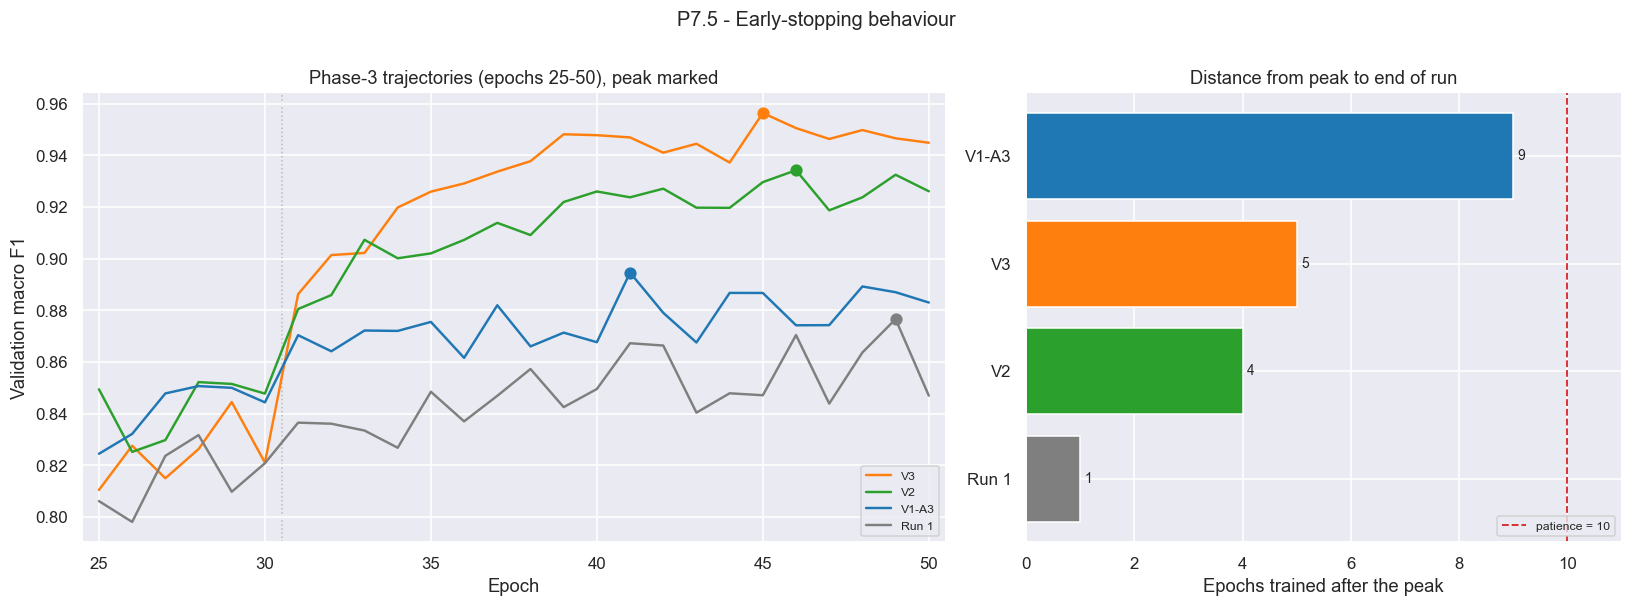

saved results\hparam_sweep\early_stopping_analysis.png


In [8]:
fig, (ax_traj, ax_gap) = plt.subplots(
    1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.45, 1]}
)

palette = {"Run 1": "#7f7f7f", "V1-A3": "#1f77b4", "V2": "#2ca02c", "V3": "#ff7f0e"}
for _, r in completed.iterrows():
    df = pd.read_csv(ROOT / r["run_dir"] / "metrics.csv")
    window = df[df["epoch"] >= 25]
    label = RUN_LABEL.get(r["experiment"], r["experiment"])
    color = palette.get(label, "#333333")
    ax_traj.plot(
        window["epoch"], window["val_macro_f1"], color=color, linewidth=1.6, label=label
    )
    peak = df.loc[df["val_macro_f1"].idxmax()]
    ax_traj.plot(peak["epoch"], peak["val_macro_f1"], marker="o", markersize=7, color=color)

ax_traj.axvline(30.5, color="#bbbbbb", linestyle=":", linewidth=1.0, zorder=0)
ax_traj.set_xlabel("Epoch")
ax_traj.set_ylabel("Validation macro F1")
ax_traj.set_title("Phase-3 trajectories (epochs 25-50), peak marked")
ax_traj.set_xlim(24.5, 50.5)
ax_traj.legend(loc="lower right", fontsize=8)

gap = early.sort_values("epochs_after_peak")
bars = ax_gap.barh(
    gap["run"], gap["epochs_after_peak"], color=[palette.get(r, "#333333") for r in gap["run"]]
)
ax_gap.bar_label(bars, padding=3, fontsize=9)
ax_gap.axvline(10, color="#d62728", linestyle="--", linewidth=1.2, label="patience = 10")
ax_gap.set_xlabel("Epochs trained after the peak")
ax_gap.set_title("Distance from peak to end of run")
ax_gap.set_xlim(0, 11)
ax_gap.legend(loc="lower right", fontsize=8)

fig.suptitle("P7.5 - Early-stopping behaviour", fontsize=13, y=1.0)
fig.tight_layout()
out = RESULTS / "early_stopping_analysis.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print("saved", out.relative_to(ROOT))


**Reading the stopping behaviour.** No run triggered early stopping - all four completed the
full 50 epochs, and no run ever accumulated 10 non-improving epochs. That is not because the
models kept improving: peaks landed at epochs 41-49, and the winner peaked at epoch 45 then
fell from 0.9564 to 0.9449 by epoch 50 as the cosine schedule reached its floor.

The practical implication is that **early stopping never protected the best checkpoint**; the
`is_better_checkpoint` selection rule did. It also means the 50-epoch budget is slightly
longer than necessary for this configuration - a shorter phase 3 would have produced the same
`best.pth` with less compute, which is worth noting for the LOSO folds in Phase 9 where the
same schedule is repeated 8 times.

**Which "peak" this section uses.** The table above reads the highest epoch-level
`val_macro_f1` straight from `metrics.csv`. Section 1's summary table instead reports the
metrics stored *inside* each run's `best.pth`, which `is_better_checkpoint` selects using a
0.005 tie window on macro F1 with min-class accuracy as the tie-breaker. For Run 1, V1-A3 and
V3 the two agree exactly. For V2 they do not: `metrics.csv` peaks at epoch 46 (0.934241), but
epoch 45 (0.929634) is within the 0.005 window and wins on min-class accuracy, so `best.pth`
holds epoch 45. That is the tie-break rule doing its job, not an inconsistency between the two
tables.


## 4. Batch size and loss weighting - held fixed, not compared

The plan's sweep menu lists batch size and loss weighting as candidate axes. Neither was
varied: P7.3 spent its three variations on the learning rate, and the remaining axes were
left at their P7.1 values. This section records those values and the reasoning, so the absence
of a comparison is a documented decision rather than an omission.


In [9]:
fixed = pd.DataFrame(
    [
        ("training.batch_size", "16", "P5.8 VRAM budget; not varied in P7.3"),
        ("training.loss.alpha", "0.7", "P7.1 baseline; not varied in P7.3"),
        ("training.loss.beta", "0.3", "P7.1 baseline; not varied in P7.3"),
        ("training.loss.class_weighted", "true", "inverse-frequency CE; not varied in P7.3"),
        ("training.epochs", "50", "3-phase schedule 10 / 20 / 20"),
        ("training.optimizer", "adamw", "weight_decay 1e-4, cosine annealing"),
        ("data.enhancement_method", "funie_gan", "held for the Phase 10 ablation"),
        ("model.stereo.enabled", "true", "held for the Phase 10 ablation"),
        ("model.text_guidance.enabled", "true", "held for the Phase 10 ablation"),
    ],
    columns=["setting", "value", "status"],
)
display(fixed)


,setting,value,status
0,training.batch_size,16,P5.8 VRAM budget; not varied in P7.3
1,training.loss.alpha,0.7,P7.1 baseline; not varied in P7.3
2,training.loss.beta,0.3,P7.1 baseline; not varied in P7.3
3,training.loss.class_weighted,true,inverse-frequency CE; not varied in P7.3
4,training.epochs,50,3-phase schedule 10 / 20 / 20
5,training.optimizer,adamw,"weight_decay 1e-4, cosine annealing"
6,data.enhancement_method,funie_gan,held for the Phase 10 ablation
7,model.stereo.enabled,true,held for the Phase 10 ablation
8,model.text_guidance.enabled,true,held for the Phase 10 ablation


,gesture_id,class,train_count,weight
0,0,start_comm,1274,0.158957
1,1,end_comm,922,0.219644
2,2,up,246,0.823217
3,3,down,324,0.625035
4,4,photo,647,0.313001
5,5,backwards,393,0.515296
6,6,carry,501,0.404214
7,7,boat,259,0.781897
8,8,here,183,1.106620
9,9,mosaic,158,1.281718


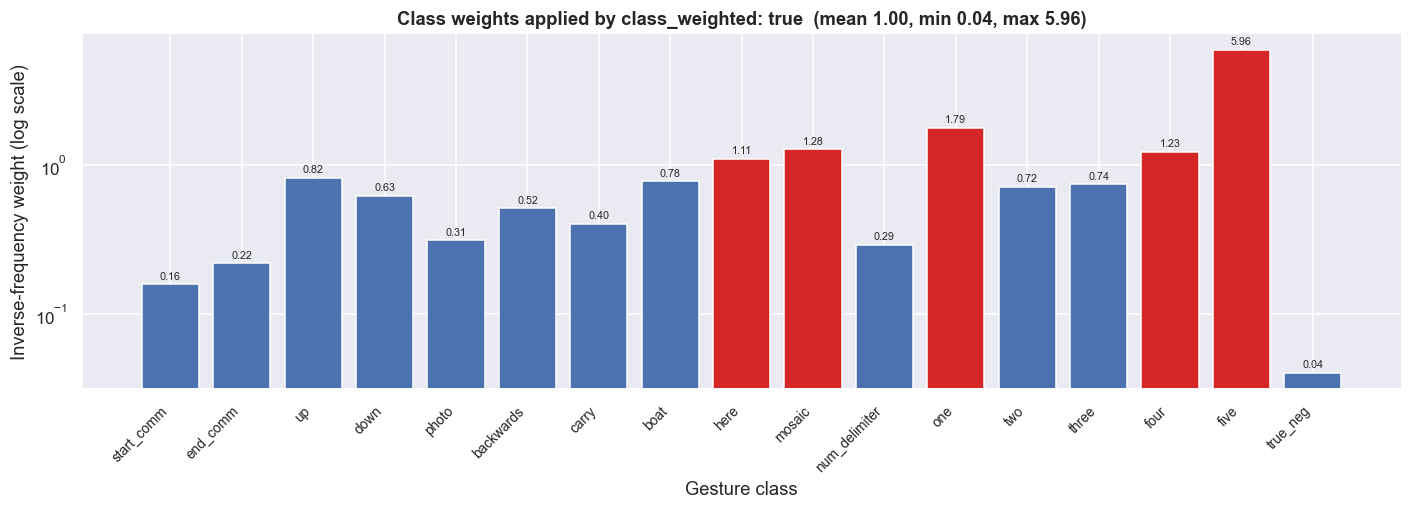

saved results\hparam_sweep\class_weights.png


In [10]:
train_df = pd.read_csv(SPLITS / "standard_train.csv")
weights = compute_class_weights(SPLITS / "standard_train.csv", num_classes=17).numpy()
names = (
    train_df[["gesture_id", "gesture_label"]]
    .drop_duplicates()
    .set_index("gesture_id")["gesture_label"]
)
counts = train_df["gesture_id"].value_counts()

wdf = pd.DataFrame({"gesture_id": range(17)})
wdf["class"] = wdf["gesture_id"].map(names)
wdf["train_count"] = wdf["gesture_id"].map(counts)
wdf["weight"] = weights
display(wdf)

fig, ax = plt.subplots(figsize=(13, 4.8))
colors = ["#d62728" if w >= 1.0 else "#4c72b0" for w in wdf["weight"]]
bars = ax.bar(wdf["class"], wdf["weight"], color=colors)
ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=7)
ax.set_yscale("log")
ax.set_ylabel("Inverse-frequency weight (log scale)")
ax.set_xlabel("Gesture class")
ax.set_title(
    "Class weights applied by class_weighted: true  "
    f"(mean {wdf['weight'].mean():.2f}, min {wdf['weight'].min():.2f}, "
    f"max {wdf['weight'].max():.2f})",
    fontweight="bold",
)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.tight_layout()
out = RESULTS / "class_weights.png"
fig.savefig(out, dpi=150, bbox_inches="tight")
plt.show()
print("saved", out.relative_to(ROOT))


**Why neither axis was swept.** The learning-rate axis was still responding and the sweep cap
was three variations, so the budget went there. Batch size 16 came from the P5.8 VRAM probe and
changing it would have altered the effective schedule as well as the batch statistic; loss
weighting is the subject of a dedicated question that belongs with the component ablations,
not with a schedule sweep. Both remain available as future single-axis runs.

**What the class weights do.** `class_weighted: true` replaces plain cross-entropy with
inverse-frequency weighting normalised to mean 1.0, so every class contributes an equal share
of the loss regardless of how many frames it has. The range is wide: `five` (34 training
frames) gets 5.96, while `true_neg` (5,032 frames, 43.8% of the data) gets 0.04. That is what
keeps macro F1 - which weights every class equally - aligned with the training objective.


## 5. Best configuration

The winning run is whatever the P7.3 selection rule named, not something re-derived here. The
rule is: highest validation macro F1, with min-class accuracy as tie-breaker.


In [11]:
winner = completed.sort_values("best_val_macro_f1", ascending=False).iloc[0]
wcfg = load_merged_config(ROOT / winner["run_dir"] / "config.yaml")

final_rows = [
    ("experiment", winner["experiment"]),
    ("config", f"configs/{winner['experiment']}.yaml"),
    ("run directory", winner["run_dir"]),
    ("best epoch", int(winner["best_epoch"])),
    ("val macro F1", f"{winner['best_val_macro_f1']:.6f}"),
    ("val accuracy", f"{winner['best_val_accuracy']:.6f}"),
    ("val min-class accuracy", f"{winner['best_val_min_class_accuracy']:.6f}"),
    ("val loss", f"{winner['best_val_loss']:.6f}"),
    ("wall time", winner["wall_time_hms"]),
    ("training.base_lr", f"{wcfg['training']['base_lr']:.1e}"),
    ("phase1.lr_scale", wcfg["training"]["phases"]["phase1"]["lr_scale"]),
    ("phase2.lr_scale", wcfg["training"]["phases"]["phase2"]["lr_scale"]),
    ("phase3.lr_scale", wcfg["training"]["phases"]["phase3"]["lr_scale"]),
    ("training.batch_size", wcfg["training"]["batch_size"]),
    ("training.epochs", wcfg["training"]["epochs"]),
    ("training.seed", wcfg["training"]["seed"]),
    ("loss.alpha / beta", f"{wcfg['training']['loss']['alpha']} / {wcfg['training']['loss']['beta']}"),
    ("loss.class_weighted", wcfg["training"]["loss"]["class_weighted"]),
    ("data.enhancement_method", wcfg["data"]["enhancement_method"]),
    ("model.stereo.enabled", wcfg["model"]["stereo"]["enabled"]),
    ("model.text_guidance.enabled", wcfg["model"]["text_guidance"]["enabled"]),
]

final_table = pd.DataFrame(final_rows, columns=["field", "value"])
display(final_table)

final_table.to_csv(RESULTS / "final_config_table.csv", index=False)
print("saved", (RESULTS / "final_config_table.csv").relative_to(ROOT))

print()
print("FROZEN CHECKPOINT : checkpoints/sense_final_standard_split.pth")
print(f"SOURCE RUN        : {winner['run_dir']}")
print(f"BEST EPOCH        : {int(winner['best_epoch'])}")
print(f"VAL MACRO F1      : {winner['best_val_macro_f1']:.6f}")
print("MANIFEST          : data/processed/final_checkpoint_manifest.md")


,field,value
0,experiment,sense_full_lr3e-4_p3lr0.3
1,config,configs/sense_full_lr3e-4_p3lr0.3.yaml
2,run directory,runs/sense_full_lr3e-4_p3lr0.3/20261119T120231Z
3,best epoch,45
4,val macro F1,0.956383
5,val accuracy,0.965923
6,val min-class accuracy,0.914286
7,val loss,0.467379
8,wall time,3h14m00s
9,training.base_lr,3.0e-04


saved results\hparam_sweep\final_config_table.csv

FROZEN CHECKPOINT : checkpoints/sense_final_standard_split.pth
SOURCE RUN        : runs/sense_full_lr3e-4_p3lr0.3/20261119T120231Z
BEST EPOCH        : 45
VAL MACRO F1      : 0.956383
MANIFEST          : data/processed/final_checkpoint_manifest.md


## 6. Selected-model training curves

The sections above compare configurations. This one looks inside the selected run.

The plot shows loss, accuracy, macro F1, and minimum class accuracy against epoch over the
full fifty-epoch budget, with the recorded training stages shaded and the selected checkpoint
marked. The selected epoch is the one the trainer saved, not necessarily the epoch with the
highest accuracy - the last two panels are what the selection rule reads.

Training accuracy is not recorded by the training loop, so the accuracy panel shows the
validation curve only.


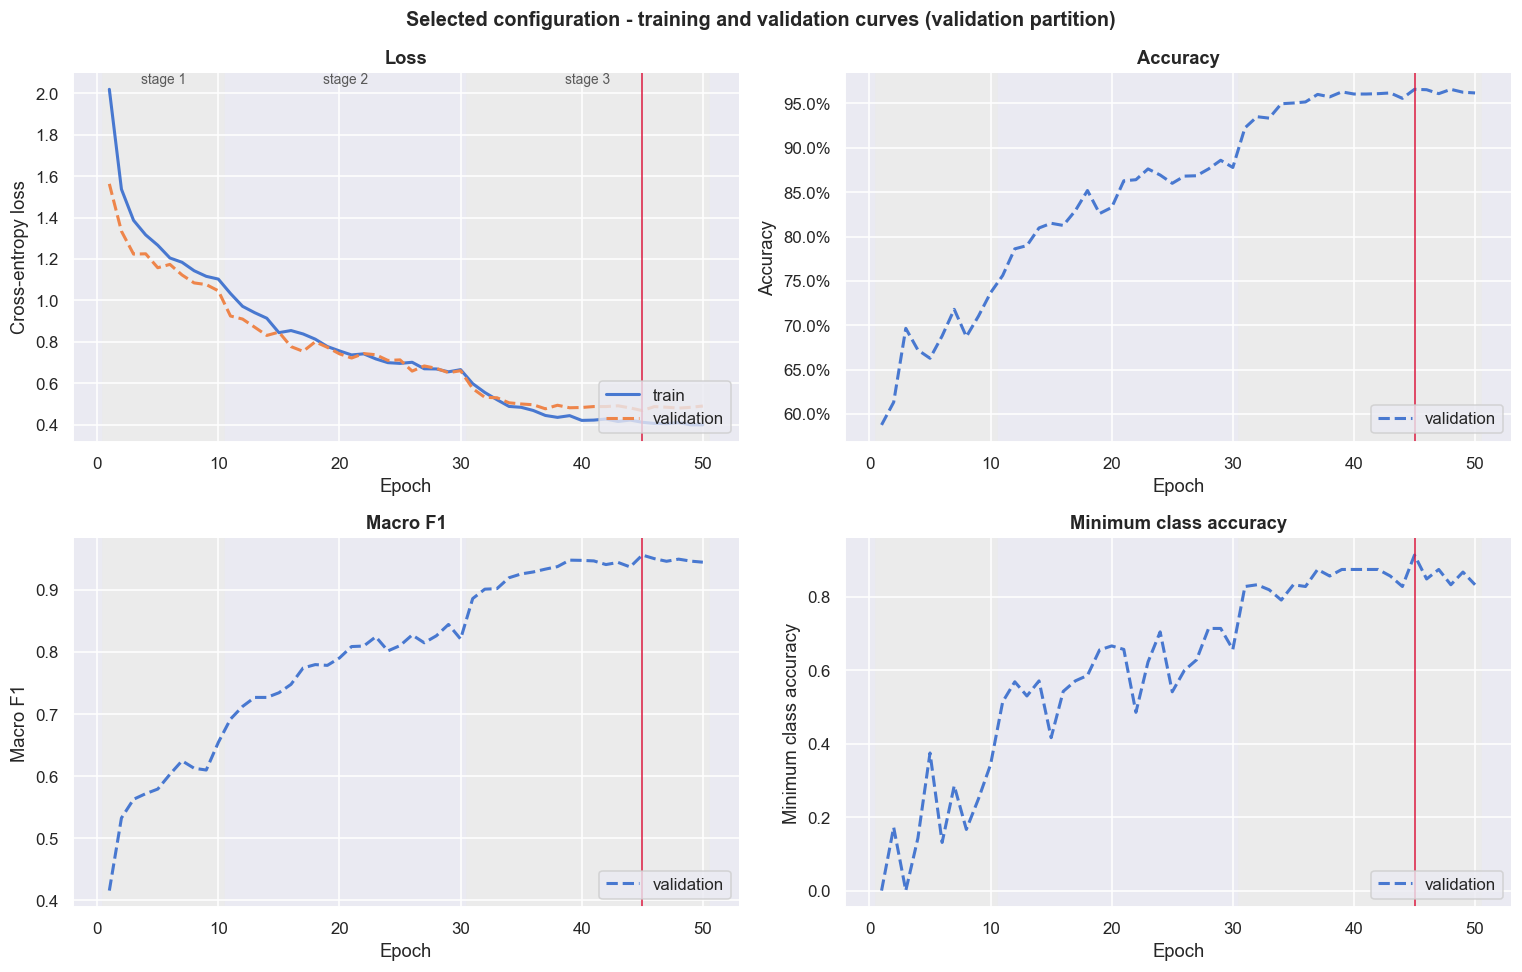

saved results\hparam_sweep\selected_model_training_curves.png


,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,val_min_class_accuracy
0,1,2.0197,1.5629,0.5878,0.4157,0.0000
10,11,1.0333,0.9245,0.7562,0.6920,0.5143
30,31,0.5976,0.5737,0.9225,0.8863,0.8286
44,45,0.4110,0.4674,0.9659,0.9564,0.9143
49,50,0.3983,0.4896,0.9619,0.9449,0.8333



selected epoch          : 45
macro F1 at selection   : 0.956383
minimum class acc.      : 0.914286
epochs completed        : 50 / 50
stages recorded         : phase1, phase2, phase3


In [12]:
import matplotlib.ticker as mticker

sel_dir = Path(winner["run_dir"])
if not sel_dir.is_absolute():
    sel_dir = ROOT / sel_dir
sel_metrics = pd.read_csv(sel_dir / "metrics.csv").sort_values("epoch").reset_index(drop=True)
sel_cfg = load_merged_config(sel_dir / "config.yaml")

max_epoch = int(sel_metrics["epoch"].max())
spans = []
for key, info in sorted(
    sel_cfg["training"]["phases"].items(), key=lambda kv: kv[1]["epochs"][0]
):
    start, end = info["epochs"][0], min(info["epochs"][1], max_epoch)
    if start <= end:
        spans.append((key, start, end))

best_epoch = int(winner["best_epoch"])

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
panels = [
    ("train_loss", "val_loss", "Loss", "Cross-entropy loss"),
    (None, "val_accuracy", "Accuracy", "Accuracy"),
    (None, "val_macro_f1", "Macro F1", "Macro F1"),
    (None, "val_min_class_accuracy", "Minimum class accuracy", "Minimum class accuracy"),
]

for ax, (train_col, val_col, title, ylabel) in zip(axes.ravel(), panels):
    for k, (_, start, end) in enumerate(spans):
        if k % 2 == 0:
            ax.axvspan(start - 0.5, end + 0.5, color="0.92", zorder=0)
    if train_col is not None:
        ax.plot(sel_metrics["epoch"], sel_metrics[train_col], linewidth=2, label="train")
    ax.plot(
        sel_metrics["epoch"], sel_metrics[val_col],
        linewidth=2, linestyle="--", label="validation",
    )
    ax.axvline(best_epoch, color="crimson", linewidth=1.3, alpha=0.75)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    if title == "Accuracy":
        ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1.0))
    if ax.get_legend_handles_labels()[0]:
        ax.legend(loc="lower right")

for k, (_, start, end) in enumerate(spans):
    axes[0, 0].text(
        (start + end) / 2,
        1.0,
        f"stage {k + 1}",
        transform=axes[0, 0].get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=9,
        color="0.35",
    )

fig.suptitle(
    "Selected configuration - training and validation curves (validation partition)",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()

out_path = RESULTS / "selected_model_training_curves.png"
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print("saved", out_path.relative_to(ROOT))

probe_epochs = [1] + [start for _, start, _ in spans[1:]] + [best_epoch, max_epoch]
probe_epochs = sorted(set(probe_epochs))
display(
    sel_metrics.loc[
        sel_metrics["epoch"].isin(probe_epochs),
        [
            "epoch", "train_loss", "val_loss", "val_accuracy",
            "val_macro_f1", "val_min_class_accuracy",
        ],
    ].round(4)
)

sel_row = sel_metrics.loc[sel_metrics["epoch"] == best_epoch].iloc[0]
print()
print(f"selected epoch          : {best_epoch}")
print(f"macro F1 at selection   : {sel_row['val_macro_f1']:.6f}")
print(f"minimum class acc.      : {sel_row['val_min_class_accuracy']:.6f}")
print(f"epochs completed        : {max_epoch} / {int(sel_cfg['training']['epochs'])}")
print(f"stages recorded         : {', '.join(key for key, _, _ in spans)}")


## 7. Summary and hand-off

**What was compared.** Three single-axis variations, all on the learning-rate axis: base LR
1e-4 -> 3e-4, then phase-3 backbone `lr_scale` 0.01 -> 0.1 -> 0.3. The configuration diff in
Section 1 confirms nothing else moved. Two `base_lr 1e-3` attempts diverged in phase 2 and are
recorded as failed attempts, not as results.

**What won.** `sense_full_lr3e-4_p3lr0.3` (run `20261119T120231Z`), best epoch 45:

| Metric | Value |
|---|---|
| `val_macro_f1` | **0.956383** |
| `val_accuracy` | 0.965923 |
| `val_min_class_accuracy` | 0.914286 |
| Margin over runner-up (V2) | +0.026749 |

The margin exceeds both the 0.005 tie window and the ≈0.019 single-seed noise band measured
from the runs sharing an identical phase-1/2 recipe, so no tie-break was needed.

**What was not compared.** Batch size (16) and loss weighting (`alpha` 0.7 / `beta` 0.3,
`class_weighted: true`) were held fixed - see Section 4.

**Where this goes.** The checkpoint is frozen at
`checkpoints/sense_final_standard_split.pth` and recorded in
`data/processed/final_checkpoint_manifest.md` (P7.4). Phase 7 is complete with this notebook;
next is Phase 8, where `scripts/evaluate.py` produces the first and only standard-split test
result for this checkpoint.
